# BERT + Multi-Kernel CNN Hybrid Model
### Binary Text Classification

**Architecture:**
- BERT (`bert-base-uncased`) as the contextual encoder
- Multi-kernel CNN (kernel sizes 2, 3, 4, 5) for local n-gram feature extraction
- Global max-pooling + concatenation + dropout + linear classifier

**Dataset assumptions:**
- Already preprocessed
- Contains a `final_text` column and a `class` column (binary: 0 / 1)
- Class imbalance is handled via weighted `CrossEntropyLoss`

## 1. Imports

In [1]:
import pandas as pd
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

import matplotlib.pyplot as plt
from transformers import BertTokenizer, BertModel

print(f"PyTorch  : {torch.__version__}")
print(f"Device   : {'cuda' if torch.cuda.is_available() else 'cpu'}")

import importlib
import improvements_3 

importlib.reload(improvements_3)

c:\Users\hp\Downloads\UNI\Spring 2026\Bachelor\Bachelor_Project\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch  : 2.12.0+cpu
Device   : cpu


<module 'improvements_3' from 'c:\\Users\\hp\\Downloads\\UNI\\Spring 2026\\Bachelor\\Bachelor_Project\\main\\improvements_3.py'>

## 2. Configuration
All hyper-parameters are declared here so they are easy to change.

In [2]:
# ── Dataset ────────────────────────────────────────────────────────────────
DATA_PATH    = r"C:\Users\hp\Downloads\UNI\Spring 2026\Bachelor\Bachelor_Project\data\improved_dataset_final.csv"  
TEXT_COL     = "final_text"
LABEL_COL    = "class"

# ── Tokenizer / BERT ───────────────────────────────────────────────────────
BERT_MODEL   = "bert-base-uncased"
MAX_LEN      = 128          # max token length (increase to 256/512 if needed)

# ── CNN ────────────────────────────────────────────────────────────────────
FILTER_SIZES = [2, 3, 4, 5] # kernel sizes
NUM_FILTERS  = 128          # output channels per kernel

# ── Training ───────────────────────────────────────────────────────────────
N_CLASSES    = 2
DROPOUT      = 0.3
BATCH_SIZE   = 16
EPOCHS       = 1
LR           = 2e-5
TEST_SIZE    = 0.2
RANDOM_STATE = 42

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Running on:", device)

Running on: cpu


## 3. Load & Split Data

In [3]:
df = pd.read_csv(DATA_PATH)

print("Dataset shape  :", df.shape)
print("Class distribution:")
print(df[LABEL_COL].value_counts())

df = df.dropna(subset=[TEXT_COL, LABEL_COL])
df[TEXT_COL] = df[TEXT_COL].astype(str).str.strip()

X = df[TEXT_COL].astype(str).to_numpy()
y = df[LABEL_COL].astype(int).to_numpy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y          # preserves class ratio in both splits
)

print(f"\nTrain samples : {len(X_train)}")
print(f"Test  samples : {len(X_test)}")

Dataset shape  : (48199, 8)
Class distribution:
class
1    27911
0    20288
Name: count, dtype: int64

Train samples : 38552
Test  samples : 9638


## 4. Class Weights (for imbalanced data)

In [4]:
# Weights are computed only from the TRAINING set to avoid data leakage
classes = np.unique(y_train)

class_weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights_tensor = torch.tensor(class_weights, dtype=torch.float).to(device)
print("Class weights:", dict(zip(classes.tolist(), class_weights.tolist())))

Class weights: {0: 1.1881896073475928, 1: 0.8632719781450132}


In [5]:
def __getitem__(self, idx):
    text = str(self.texts[idx])          # ← defensive cast guards against any stray non-str
    if not text or text.lower() == "nan":
        text = "[UNK]"                   # replace empty/NaN text with a safe fallback

    encoding = self.tokenizer(
        text,
        max_length=self.max_len,
        padding="max_length",
        truncation=True,
        return_tensors="pt"
    )
    return {
        "input_ids"     : encoding["input_ids"].squeeze(0),
        "attention_mask": encoding["attention_mask"].squeeze(0),
        "label"         : torch.tensor(self.labels[idx], dtype=torch.long)
    }

## 5. Dataset & DataLoader

In [6]:
tokenizer = BertTokenizer.from_pretrained(BERT_MODEL)


class TextDataset(Dataset):
    """Tokenises text on-the-fly and returns tensors ready for BERT."""

    def __init__(self, texts, labels, tokenizer, max_len):
        self.texts     = texts
        self.labels    = labels
        self.tokenizer = tokenizer
        self.max_len   = max_len

    def __len__(self):
        return len(self.texts)

    def __getitem__(self, idx):
        encoding = self.tokenizer(
            self.texts[idx],
            max_length=self.max_len,
            padding="max_length",
            truncation=True,
            return_tensors="pt"
        )
        return {
            "input_ids"     : encoding["input_ids"].squeeze(0),      # [max_len]
            "attention_mask": encoding["attention_mask"].squeeze(0),  # [max_len]
            "label"         : torch.tensor(self.labels[idx], dtype=torch.long)
        }


train_dataset = TextDataset(X_train, y_train, tokenizer, MAX_LEN)
test_dataset  = TextDataset(X_test,  y_test,  tokenizer, MAX_LEN)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader  = DataLoader(test_dataset,  batch_size=BATCH_SIZE, shuffle=False)

print(f"Train batches : {len(train_loader)}")
print(f"Test  batches : {len(test_loader)}")

Train batches : 2410
Test  batches : 603


## 6. Model Architecture — BERT + Multi-Kernel CNN

In [7]:
class BertTextCNN(nn.Module):
    """
    Hybrid BERT + multi-kernel CNN classifier.

    Flow:
      text  →  BERT  →  last_hidden_state  [B, L, 768]
            →  permute                     [B, 768, L]
            →  Conv1d (×4 kernel sizes)    [B, num_filters, L']
            →  global max-pool             [B, num_filters]  (×4)
            →  concat                      [B, 4 × num_filters]
            →  dropout  →  linear          [B, n_classes]
    """

    def __init__(
        self,
        bert_model_name = BERT_MODEL,
        n_classes        = N_CLASSES,
        filter_sizes     = FILTER_SIZES,
        num_filters      = NUM_FILTERS,
        dropout          = DROPOUT,
        freeze_bert      = False   # set True to fine-tune CNN head only
    ):
        super().__init__()

        # ── BERT encoder ──────────────────────────────────────────────────
        self.bert = BertModel.from_pretrained(bert_model_name)

        if freeze_bert:
            for param in self.bert.parameters():
                param.requires_grad = False

        embedding_dim = self.bert.config.hidden_size   # 768 for base

        # ── Multi-kernel CNN ──────────────────────────────────────────────
        self.convs = nn.ModuleList([
            nn.Conv1d(
                in_channels  = embedding_dim,
                out_channels = num_filters,
                kernel_size  = fs
            )
            for fs in filter_sizes
        ])

        self.dropout = nn.Dropout(dropout)

        # ── Classifier ────────────────────────────────────────────────────
        self.fc = nn.Linear(len(filter_sizes) * num_filters, n_classes)

    # ------------------------------------------------------------------
    def forward(self, input_ids, attention_mask):

        # BERT: [B, L, 768]
        bert_out = self.bert(input_ids=input_ids, attention_mask=attention_mask)
        x = bert_out.last_hidden_state          # [B, L, 768]

        # Conv1D expects [B, channels, L]
        x = x.permute(0, 2, 1)                  # [B, 768, L]

        # Apply each kernel, ReLU, global max-pool
        pooled = []
        for conv in self.convs:
            c = F.relu(conv(x))                 # [B, num_filters, L']
            p = F.max_pool1d(c, c.size(2))      # [B, num_filters, 1]
            pooled.append(p.squeeze(2))         # [B, num_filters]

        x = torch.cat(pooled, dim=1)            # [B, 4 × num_filters]
        x = self.dropout(x)
        return self.fc(x)                       # [B, n_classes]

## 7. Initialise Model, Loss, Optimiser

In [8]:
model = BertTextCNN().to(device)

# Weighted loss handles class imbalance — weights computed from training set
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

optimizer = torch.optim.Adam(model.parameters(), lr=LR)

# Optional: linear warm-up + decay scheduler
from transformers import get_linear_schedule_with_warmup

total_steps   = len(train_loader) * EPOCHS
warmup_steps  = int(0.1 * total_steps)   # 10 % warm-up

scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps   = warmup_steps,
    num_training_steps = total_steps
)

total_params     = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"Total params    : {total_params:,}")
print(f"Trainable params: {trainable_params:,}")

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 1344.58it/s]
BertModel LOAD REPORT from: bert-base-uncased
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Total params    : 110,860,034
Trainable params: 110,860,034


## 8. Training & Evaluation Helpers

In [9]:
def train_one_epoch(model, loader, criterion, optimizer, scheduler):
    """One full pass over the training set. Returns average loss."""
    model.train()
    total_loss = 0.0

    for batch in loader:
        input_ids      = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels         = batch["label"].to(device)

        optimizer.zero_grad()

        logits = model(input_ids, attention_mask)   # [B, n_classes]
        loss   = criterion(logits, labels)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)  # gradient clipping
        optimizer.step()
        scheduler.step()

        total_loss += loss.item()

    return total_loss / len(loader)


def evaluate(model, loader):
    """Returns (predictions, true_labels) as numpy arrays."""
    model.eval()
    preds_list, true_list = [], []

    with torch.no_grad():
        for batch in loader:
            input_ids      = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels         = batch["label"].to(device)

            logits = model(input_ids, attention_mask)
            preds  = torch.argmax(logits, dim=1)

            preds_list.extend(preds.cpu().numpy())
            true_list.extend(labels.cpu().numpy())

    return np.array(preds_list), np.array(true_list)


def print_metrics(true, preds, epoch=None, loss=None):
    header = f"── Epoch {epoch} " if epoch is not None else "── Final Results "
    if loss is not None:
        header += f"| Train Loss: {loss:.4f} "
    print(header + "─" * max(0, 60 - len(header)))
    print(f"  Accuracy  : {accuracy_score(true, preds):.4f}")
    print(f"  Precision : {precision_score(true, preds, zero_division=0):.4f}")
    print(f"  Recall    : {recall_score(true, preds, zero_division=0):.4f}")
    print(f"  F1 Score  : {f1_score(true, preds, zero_division=0):.4f}")

## 9. Training Loop

In [10]:
history = {"train_loss": [], "f1": [], "accuracy": []}

best_f1          = 0.0
best_model_state = None

for epoch in range(1, EPOCHS + 1):

    avg_loss = train_one_epoch(model, train_loader, criterion, optimizer, scheduler)
    preds, true = evaluate(model, test_loader)

    epoch_f1  = f1_score(true, preds, zero_division=0)
    epoch_acc = accuracy_score(true, preds)

    history["train_loss"].append(avg_loss)
    history["f1"].append(epoch_f1)
    history["accuracy"].append(epoch_acc)

    print_metrics(true, preds, epoch=epoch, loss=avg_loss)

    # Save best checkpoint by F1
    if epoch_f1 > best_f1:
        best_f1          = epoch_f1
        best_model_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        print(f"  ✔ New best model saved (F1={best_f1:.4f})")

print("\nTraining complete.")

── Epoch 1 | Train Loss: 0.3154 ────────────────────────────
  Accuracy  : 0.8915
  Precision : 0.9282
  Recall    : 0.8807
  F1 Score  : 0.9038
  ✔ New best model saved (F1=0.9038)

Training complete.


## 10. Training Curves

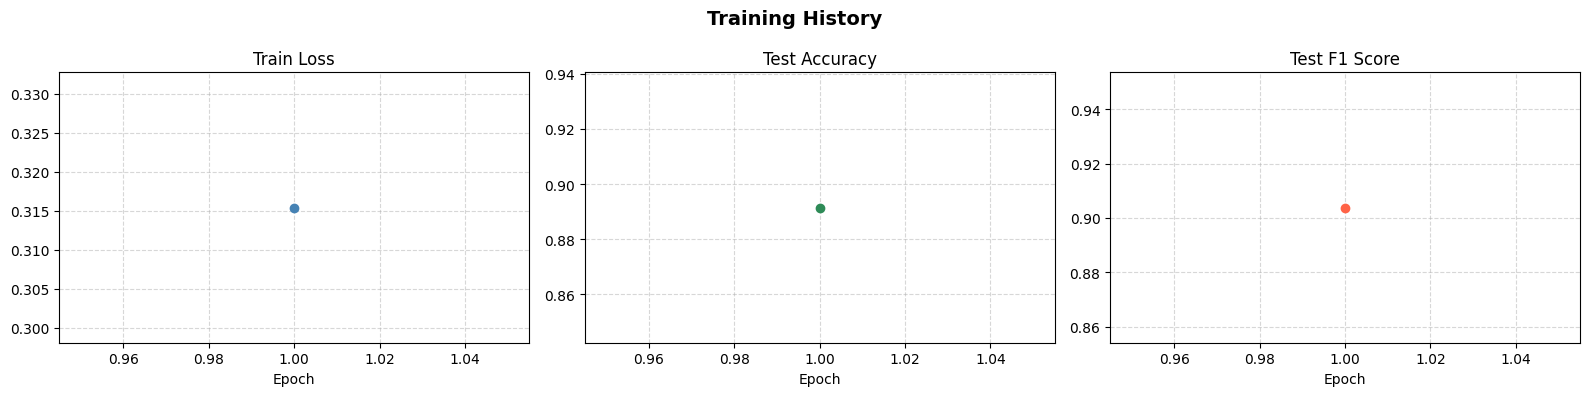

In [11]:
epochs_range = range(1, EPOCHS + 1)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
fig.suptitle("Training History", fontsize=14, fontweight="bold")

for ax, key, label, color in zip(
    axes,
    ["train_loss", "accuracy", "f1"],
    ["Train Loss", "Test Accuracy", "Test F1 Score"],
    ["steelblue", "seagreen", "tomato"]
):
    ax.plot(epochs_range, history[key], marker="o", color=color, linewidth=2)
    ax.set_title(label)
    ax.set_xlabel("Epoch")
    ax.grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig("training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

## 11. Final Evaluation on Best Model

In [12]:
# Load best checkpoint
model.load_state_dict(best_model_state)
model.to(device)

preds, true = evaluate(model, test_loader)

print("\n" + "=" * 60)
print("  FINAL TEST SET RESULTS  (best checkpoint by F1)")
print("=" * 60)
print_metrics(true, preds)
print()
print(classification_report(true, preds, target_names=["Class 0", "Class 1"]))


  FINAL TEST SET RESULTS  (best checkpoint by F1)
── Final Results ───────────────────────────────────────────
  Accuracy  : 0.8915
  Precision : 0.9282
  Recall    : 0.8807
  F1 Score  : 0.9038

              precision    recall  f1-score   support

     Class 0       0.85      0.91      0.88      4056
     Class 1       0.93      0.88      0.90      5582

    accuracy                           0.89      9638
   macro avg       0.89      0.89      0.89      9638
weighted avg       0.89      0.89      0.89      9638



## 12. Confusion Matrix

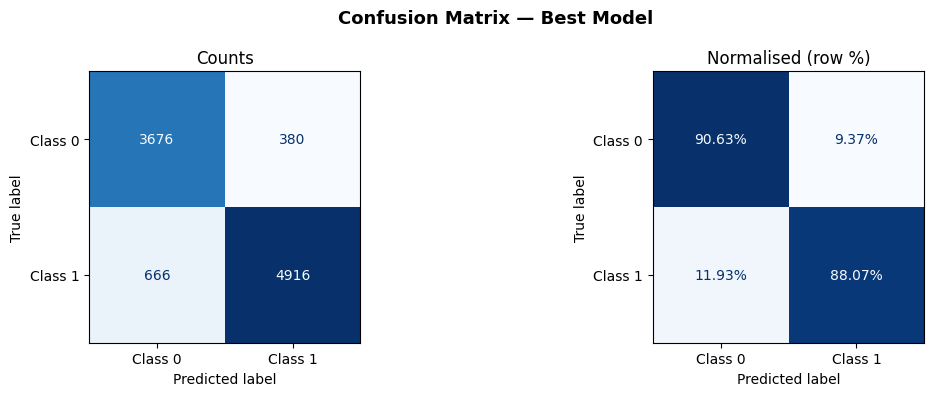

TN=3676  FP=380  FN=666  TP=4916


In [13]:
cm = confusion_matrix(true, preds)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle("Confusion Matrix — Best Model", fontsize=13, fontweight="bold")

# Raw counts
disp_counts = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["Class 0", "Class 1"])
disp_counts.plot(ax=axes[0], colorbar=False, cmap="Blues")
axes[0].set_title("Counts")

# Normalised (recall-oriented: rows sum to 1)
cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
disp_norm = ConfusionMatrixDisplay(confusion_matrix=cm_norm, display_labels=["Class 0", "Class 1"])
disp_norm.plot(ax=axes[1], colorbar=False, cmap="Blues", values_format=".2%")
axes[1].set_title("Normalised (row %)")

plt.tight_layout()
plt.savefig("confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

In [14]:
# ── Error Analysis ────────────────────────────────────────────────────────────
results_df = pd.DataFrame({
    "text"     : X_test,
    "true"     : true,
    "predicted": preds
})

results_df["correct"] = results_df["true"] == results_df["predicted"]

# Summary counts
total   = len(results_df)
correct = results_df["correct"].sum()
wrong   = total - correct

print("=" * 60)
print(f"  Total samples : {total}")
print(f"  Correct       : {correct}  ({correct/total*100:.1f}%)")
print(f"  Wrong         : {wrong}   ({wrong/total*100:.1f}%)")
print("=" * 60)

# Per-class breakdown
fp_df = results_df[(results_df["true"] == 0) & (results_df["predicted"] == 1)]  # predicted positive, actually negative
fn_df = results_df[(results_df["true"] == 1) & (results_df["predicted"] == 0)]  # predicted negative, actually positive
tp_df = results_df[(results_df["true"] == 1) & (results_df["predicted"] == 1)]
tn_df = results_df[(results_df["true"] == 0) & (results_df["predicted"] == 0)]

print(f"\n  TP (correct positives) : {len(tp_df)}")
print(f"  TN (correct negatives) : {len(tn_df)}")
print(f"  FP (false alarms)      : {len(fp_df)}")
print(f"  FN (missed positives)  : {len(fn_df)}")

# Sample previews
N_SHOW = 10   # how many examples to display per category

print(f"\n{'─'*60}")
print(f"  FALSE POSITIVES — model said 1, truth is 0 (n={len(fp_df)})")
print(f"{'─'*60}")
for i, row in fp_df.head(N_SHOW).iterrows():
    print(f"  [{i}] {row['text'][:120]}")

print(f"\n{'─'*60}")
print(f"  FALSE NEGATIVES — model said 0, truth is 1 (n={len(fn_df)})")
print(f"{'─'*60}")
for i, row in fn_df.head(N_SHOW).iterrows():
    print(f"  [{i}] {row['text'][:120]}")

  Total samples : 9638
  Correct       : 8592  (89.1%)
  Wrong         : 1046   (10.9%)

  TP (correct positives) : 4916
  TN (correct negatives) : 3676
  FP (false alarms)      : 380
  FN (missed positives)  : 666

────────────────────────────────────────────────────────────
  FALSE POSITIVES — model said 1, truth is 0 (n=380)
────────────────────────────────────────────────────────────
  [8] happy halloween do not wear a racist costume and look out for your female friend tonight big party are stomping ground f
  [43] did you force yourself to be straight if you did you probably are gay
  [50] thirsty giant are always like ho ho ho
  [90] who is you what is an illegal settlement all muslim settlement were made by violence
  [93] this is islam
  [143] with it in system ill name the next one fuck your blob
  [175] your a big yute to be having slit in your brow my darg laughing out loud drop it out
  [185] rt human are genetically closer to chimp than chimp are to gorilla but we are all 

In [15]:
import os

# Create folder
os.makedirs("../saved_model", exist_ok=True)

# Save model weights
torch.save(model.state_dict(), "../saved_model/bert_cnn_model.pt")

# Save tokenizer
tokenizer.save_pretrained("../saved_model/tokenizer")

print("Model and tokenizer saved successfully.")

Model and tokenizer saved successfully.
